# nb4 — L-BFGS versus Adam on the quartz/Si fit: same data, same scaled parameters, same loss, same three starts

`torch.optim.LBFGS` (strong-Wolfe line search, history 20, float64) on the multiplicative factors
$u = p/p^{(0)}$ with the MAE + log-cosh loss of nb3, from the three starts of nb3.  Every accepted iterate and
the cumulative number of function (= gradient) evaluations are recorded.  Each run is stopped when the loss
stops changing (tolerance) or after `MAX_ITER` iterations; the iteration at which it first reaches the loss level
of the 20 000-iteration Adam run is recorded.  L-BFGS is also run with the plain MAE and the rMSE losses (JSON only).

The L-BFGS paths are projected onto the **same** PCA planes as Fig. 4 (Phase-I plane of each start and the
shared Phase-II plane, loaded from `results/nb3_trajectories.npz`), with Adam's path drawn faintly.

Outputs: `figs/fig5_lbfgs_trajectory.*`, `results/nb4.json`.

In [1]:
import sys, os, json, time
sys.path.insert(0, '../code')
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

torch.set_num_threads(int(os.environ.get('NB_THREADS', 2)))
torch.set_default_dtype(torch.float64)

import loss_landscape_viz as lv
from quartzsi_model import QuartzSiProblem, STARTS, PARAM_NAMES, PARAM_TEX, DT
import paperstyle as ps
ps.apply()
lv.LANDSCAPE_CMAP = ps.LANDSCAPE_CMAP
os.makedirs('../figs', exist_ok=True); os.makedirs('../results', exist_ok=True)

## 1. Problem and the Adam results / planes of nb3

In [2]:
P = QuartzSiProblem('../data/Reference_15min_nitrogen.txt', '../data/Quartz_Si_15min_nitrogen.txt', prepulse_ps=10.0)
L, t_r, sigma = P.L, P.t_r, P.sigma
z = np.load('../results/nb3_trajectories.npz')
ref, scale, b = z['ref'], z['scale'], int(z['boundary'])
adam = [{'params': z[f'traj{k}_params'], 'loss': z[f'traj{k}_loss'], 'label': f'Start {k+1}'} for k in range(3)]
N_ADAM = len(adam[0]['loss'])
adam_final = np.array([t['loss'][-1] for t in adam])
adam_best = np.array([t['loss'].min() for t in adam])

def load_plane(tag):
    ir = z[f'{tag}_iter_range']; ir = None if ir[0] < 0 else (int(ir[0]), int(ir[1]))
    return {'u': z[f'{tag}_u'], 'v': z[f'{tag}_v'], 'w': z[f'{tag}_w'], 'explained': z[f'{tag}_explained'], 'ref': ref, 'scale': scale, 'iter_range': ir}
planes1 = [load_plane(f'plane1_{k}') for k in range(3)]
plane2 = load_plane('plane2')
print(f'Adam: {N_ADAM} iterations per start, final losses {adam_final}, phase boundary {b}')
adam_iters_to = lambda level, k: (int(np.argmax(adam[k]['loss'] <= level)) + 1) if np.any(adam[k]['loss'] <= level) else None
print('optimum of nb3:', dict(zip(PARAM_NAMES, np.round(ref, 6))), 'loss', P.loss_np(ref))

Adam: 20000 iterations per start, final losses [0.00445223 0.00445283 0.00445179], phase boundary 1615
optimum of nb3: {'n1': np.float64(1.963902), 'k1': np.float64(0.005411), 'd1': np.float64(0.000994), 'n2': np.float64(3.447614), 'k2': np.float64(-0.001458), 'd2': np.float64(0.000381)} loss 0.004451584272274206


## 2. L-BFGS on the multiplicative factors, recording every accepted iterate and the cumulative evaluations

In [3]:
HISTORY, MAX_ITER, MAX_LS, MAX_RESTARTS, MAX_EVALS = 20, 400, 30, 3, 3000
TOL_CHANGE, TOL_GRAD, PATIENCE = 1e-12, 1e-12, 3

def lbfgs_fit(p0, kind='mae_logcosh', target=None, max_iter=MAX_ITER, history=HISTORY, max_restarts=MAX_RESTARTS, lr=1.0, label=''):
    """One L-BFGS iteration per .step() so that every accepted iterate is recorded (the curvature history persists in
    the optimiser state between calls).  When the line search can no longer decrease the loss (stall), the history is
    cleared and L-BFGS restarted from the current point (steepest-descent step), up to `max_restarts` times.
    Returns dict with params [n+1, 6] (entry 0 = start), loss [n+1], n_evals [n+1] (cumulative closure calls up to
    that iterate), evals_to_target (first iterate with loss <= target), restarts, wall time and the stop reason."""
    p0 = torch.tensor(np.asarray(p0, float), dtype=DT)
    u = torch.ones(6, dtype=DT, requires_grad=True)
    n_evals = [0]

    def make_opt():
        # max_iter=1: one L-BFGS iteration per .step(); max_eval must be set explicitly, otherwise torch gives the
        # line search max_eval - 1 = 0 evaluations and the step is always zero.
        return torch.optim.LBFGS([u], lr=lr, max_iter=1, max_eval=MAX_LS, history_size=history, line_search_fn='strong_wolfe',
                                 tolerance_grad=TOL_GRAD, tolerance_change=TOL_CHANGE)
    opt = make_opt()

    def closure():
        opt.zero_grad()
        loss = P.loss_torch(u * p0, kind)
        loss.backward()
        n_evals[0] += 1
        return loss

    with torch.no_grad():
        l0 = P.loss_torch(u * p0, kind).item()
    hist_p, hist_l, hist_e = [(u * p0).detach().numpy().copy()], [l0], [0]
    t0 = time.time(); reason = f'max_iter = {max_iter}'; stall = 0; hit = None; restarts = 0; restart_at = []
    for it in range(1, max_iter + 1):
        opt.step(closure)
        with torch.no_grad():
            l = P.loss_torch(u * p0, kind).item()
        if not np.isfinite(l):
            with torch.no_grad():
                u.copy_(torch.tensor(hist_p[-1] / p0.numpy(), dtype=DT))
            reason = 'line search diverged (non-finite loss); reverted to the last finite iterate'; break
        if n_evals[0] > MAX_EVALS:
            reason = f'evaluation budget {MAX_EVALS} exhausted'; break
        hist_p.append((u * p0).detach().numpy().copy()); hist_l.append(l); hist_e.append(n_evals[0])
        if target is not None and hit is None and l <= target:
            hit = (it, n_evals[0])
        stall = stall + 1 if abs(hist_l[-2] - l) <= TOL_CHANGE * max(1.0, abs(l)) else 0
        if stall >= PATIENCE:
            if restarts < max_restarts:
                restarts += 1; restart_at.append((it, n_evals[0])); stall = 0
                opt = make_opt()
            else:
                reason = f'line search stalled (loss change < {TOL_CHANGE:g} for {PATIENCE} iterations) after {restarts} restarts'; break
    wall = time.time() - t0
    out = dict(params=np.array(hist_p), loss=np.array(hist_l), n_evals=np.array(hist_e), wall=wall, reason=reason,
               evals_to_target=hit, kind=kind, restarts=restarts, restart_at=restart_at, lr=lr)
    print(f"[{label}] {len(hist_l)-1} iterations, {n_evals[0]} evaluations, {restarts} restarts, {wall:.1f} s ({1e3*wall/max(n_evals[0],1):.1f} ms/eval), "
          f"final loss {hist_l[-1]:.6e}, stop: {reason}" + (f"; reached the Adam level {target:.4e} at iteration {hit[0]} / {hit[1]} evaluations" if hit else
          (f"; never reached the Adam level {target:.4e}" if target is not None else '')), flush=True)
    return out

runs = [lbfgs_fit(s, target=adam_final[k], label=f'L-BFGS start {k+1}') for k, s in enumerate(STARTS)]

[L-BFGS start 1] 67 iterations, 250 evaluations, 3 restarts, 1.4 s (5.5 ms/eval), final loss 4.617188e-03, stop: line search stalled (loss change < 1e-12 for 3 iterations) after 3 restarts; never reached the Adam level 4.4522e-03


[L-BFGS start 2] 74 iterations, 272 evaluations, 3 restarts, 1.5 s (5.4 ms/eval), final loss 4.617770e-03, stop: line search stalled (loss change < 1e-12 for 3 iterations) after 3 restarts; never reached the Adam level 4.4528e-03


[L-BFGS start 3] 80 iterations, 299 evaluations, 3 restarts, 1.6 s (5.5 ms/eval), final loss 4.617309e-03, stop: line search stalled (loss change < 1e-12 for 3 iterations) after 3 restarts; never reached the Adam level 4.4518e-03


## 3. Where each optimiser ends along the $n\,d$ valley, and the loss along the line between the two end points

In [4]:
def nd_row(p):
    return dict(n1=p[0], k1=p[1], d1_um=p[2] * 1e6, n2=p[3], k2=p[4], d2_um=p[5] * 1e6, n1d1_mm=p[0] * p[2] * 1e3, n2d2_mm=p[3] * p[5] * 1e3)
# straight line from the L-BFGS end point to the Adam end point (start 1): barrier or monotonic descent?
alphas = np.linspace(-0.2, 1.2, 29)
line_loss = [P.loss_np(runs[0]['params'][-1] + a * (adam[0]['params'][-1] - runs[0]['params'][-1])) for a in alphas]
print('loss along the straight line L-BFGS end (alpha=0) -> Adam end (alpha=1), start 1:')
print('  ', ', '.join(f'{a:.1f}: {l:.4e}' for a, l in zip(alphas[::4], line_loss[::4])))
# loss along the steepest-descent direction at the L-BFGS end point (why the line search stops: the V-shaped MAE kink)
u_end = torch.tensor(runs[0]['params'][-1] / STARTS[0], dtype=DT, requires_grad=True)
l_end = P.loss_torch(u_end * torch.tensor(STARTS[0], dtype=DT)); l_end.backward(); g_end = u_end.grad.numpy().copy()
probe_t = np.logspace(-8, -2, 13)
probe_loss = [P.loss_np((u_end.detach().numpy() - t * g_end) * STARTS[0]) for t in probe_t]
print('loss change along -grad at the L-BFGS end point (start 1), step t in u:')
print('  ', ', '.join(f't={t:.0e}: {l - l_end.item():+.1e}' for t, l in zip(probe_t[::2], probe_loss[::2])))
print(f'  |grad| at the L-BFGS end point {np.linalg.norm(g_end):.3e}; at the Adam end point', end=' ')
u_a = torch.tensor(adam[0]['params'][-1] / STARTS[0], dtype=DT, requires_grad=True)
P.loss_torch(u_a * torch.tensor(STARTS[0], dtype=DT)).backward(); print(f'{np.linalg.norm(u_a.grad.numpy()):.3e}')

print(f"{'':18s} {'n1':>8s} {'k1':>9s} {'d1/um':>8s} {'n2':>8s} {'k2':>10s} {'d2/um':>8s} {'n1d1/mm':>9s} {'n2d2/mm':>9s} {'loss':>11s} {'evals':>6s}")
for k in range(3):
    for name, p, l, e in [(f'Adam, start {k+1}', adam[k]['params'][-1], adam[k]['loss'][-1], N_ADAM),
                          (f'L-BFGS, start {k+1}', runs[k]['params'][-1], runs[k]['loss'][-1], runs[k]['n_evals'][-1])]:
        r = nd_row(p)
        print(f"{name:18s} {r['n1']:8.4f} {r['k1']:9.5f} {r['d1_um']:8.1f} {r['n2']:8.4f} {r['k2']:+10.5f} {r['d2_um']:8.1f} {r['n1d1_mm']:9.4f} {r['n2d2_mm']:9.4f} {l:11.4e} {e:6d}")

loss along the straight line L-BFGS end (alpha=0) -> Adam end (alpha=1), start 1:
   -0.2: 4.6802e-03, -0.0: 4.6172e-03, 0.2: 4.5647e-03, 0.4: 4.5202e-03, 0.6: 4.4869e-03, 0.8: 4.4631e-03, 1.0: 4.4522e-03, 1.2: 4.4652e-03
loss change along -grad at the L-BFGS end point (start 1), step t in u:
   t=1e-08: +6.4e-12, t=1e-07: +9.2e-11, t=1e-06: +9.5e-10, t=1e-05: +1.3e-08, t=1e-04: +1.3e-07, t=1e-03: +2.3e-06, t=1e-02: +9.8e-05
  |grad| at the L-BFGS end point 3.648e-02; at the Adam end point 3.492e-02
                         n1        k1    d1/um       n2         k2    d2/um   n1d1/mm   n2d2/mm        loss  evals
Adam, start 1        1.9639   0.00541    994.3   3.4478   -0.00144    381.4    1.9526    1.3150  4.4522e-03  20000
L-BFGS, start 1      1.9536   0.00305    999.6   3.4954   +0.00436    376.1    1.9528    1.3146  4.6172e-03    250
Adam, start 2        1.9637   0.00540    994.4   3.4488   -0.00140    381.3    1.9527    1.3150  4.4528e-03  20000
L-BFGS, start 2      1.9530   0.003

## 4. Robustness: L-BFGS with the plain MAE and the rMSE losses (JSON only)

In [5]:
other = {}
for kind in ('mae', 'rmse', 'logcosh'):
    other[kind] = [lbfgs_fit(s, kind=kind, label=f'L-BFGS {kind} start {k+1}') for k, s in enumerate(STARTS)]
    for k, s in enumerate(STARTS):          # a run whose line search diverged is repeated once with a damped first step (lr = 0.1)
        if other[kind][k]['reason'].startswith('line search diverged'):
            other[kind][k] = lbfgs_fit(s, kind=kind, lr=0.1, label=f'L-BFGS {kind} start {k+1}, retry lr 0.1')
    for k in range(3):
        r = nd_row(other[kind][k]['params'][-1])
        print(f"   {kind:4s} start {k+1}: d1 {r['d1_um']:.1f} um, d2 {r['d2_um']:.1f} um, n1d1 {r['n1d1_mm']:.4f} mm, n2d2 {r['n2d2_mm']:.4f} mm, "
              f"MAE+logcosh at this point {P.loss_np(other[kind][k]['params'][-1]):.4e}")

[L-BFGS mae start 1] 56 iterations, 258 evaluations, 3 restarts, 1.4 s (5.5 ms/eval), final loss 4.550733e-03, stop: line search stalled (loss change < 1e-12 for 3 iterations) after 3 restarts


[L-BFGS mae start 2] 103 iterations, 391 evaluations, 3 restarts, 2.0 s (5.2 ms/eval), final loss 4.539833e-03, stop: line search stalled (loss change < 1e-12 for 3 iterations) after 3 restarts


[L-BFGS mae start 3] 121 iterations, 392 evaluations, 3 restarts, 2.0 s (5.1 ms/eval), final loss 4.539990e-03, stop: line search stalled (loss change < 1e-12 for 3 iterations) after 3 restarts


   mae  start 1: d1 997.5 um, d2 378.0 um, n1d1 1.9526 mm, n2d2 1.3148 mm, MAE+logcosh at this point 4.6285e-03
   mae  start 2: d1 1000.0 um, d2 375.7 um, n1d1 1.9528 mm, n2d2 1.3146 mm, MAE+logcosh at this point 4.6178e-03
   mae  start 3: d1 999.8 um, d2 375.8 um, n1d1 1.9528 mm, n2d2 1.3146 mm, MAE+logcosh at this point 4.6178e-03


[L-BFGS rmse start 1] 80 iterations, 181 evaluations, 3 restarts, 1.0 s (5.4 ms/eval), final loss 1.123980e-02, stop: line search stalled (loss change < 1e-12 for 3 iterations) after 3 restarts


[L-BFGS rmse start 2] 77 iterations, 236 evaluations, 0 restarts, 1.3 s (5.4 ms/eval), final loss 1.787488e-01, stop: line search diverged (non-finite loss); reverted to the last finite iterate


... (3 outputs left out)

[L-BFGS logcosh start 1] 400 iterations, 908 evaluations, 0 restarts, 4.8 s (5.3 ms/eval), final loss 6.898200e-05, stop: max_iter = 400


[L-BFGS logcosh start 2] 211 iterations, 484 evaluations, 3 restarts, 2.6 s (5.3 ms/eval), final loss 6.311684e-05, stop: line search stalled (loss change < 1e-12 for 3 iterations) after 3 restarts


[L-BFGS logcosh start 3] 87 iterations, 178 evaluations, 3 restarts, 1.0 s (5.4 ms/eval), final loss 6.311684e-05, stop: line search stalled (loss change < 1e-12 for 3 iterations) after 3 restarts


   logcosh start 1: d1 987.7 um, d2 388.1 um, n1d1 1.9527 mm, n2d2 1.3149 mm, MAE+logcosh at this point 4.8244e-03
   logcosh start 2: d1 977.7 um, d2 398.1 um, n1d1 1.9523 mm, n2d2 1.3153 mm, MAE+logcosh at this point 4.7584e-03
   logcosh start 3: d1 977.7 um, d2 398.1 um, n1d1 1.9523 mm, n2d2 1.3153 mm, MAE+logcosh at this point 4.7584e-03


## 5. Plot helpers (Figure 5 itself is drawn at the end, after the loop-1 checks)

In [6]:
MILESTONES = [10, 100, 1000, 10000]

def draw_path(ax, a, bb, color, lw=1.1, offset=0, milestones=MILESTONES, star=True, annotate=True, zorder=5, marker_every=None):
    pts = np.column_stack([a, bb]).reshape(-1, 1, 2)
    seg = np.concatenate([pts[:-1], pts[1:]], axis=1)
    cols = [plt.matplotlib.colors.to_rgba(color, al) for al in np.linspace(0.35, 1.0, max(len(seg), 1))]
    ax.add_collection(LineCollection(seg, colors=cols, linewidths=lw, zorder=zorder, capstyle='round'))
    ax.plot(a[0], bb[0], 'o', color=color, ms=4.5, mec='white', mew=0.6, zorder=zorder + 1)
    if star:
        ax.plot(a[-1], bb[-1], '*', color=color, ms=8, mec='white', mew=0.5, zorder=zorder + 2)
    if marker_every:
        ax.plot(a[1:-1], bb[1:-1], 'o', color='white', ms=2.2, mec=color, mew=0.7, zorder=zorder + 1)
    for m in milestones:
        i = m - offset
        if 0 < i < len(a) - 1:
            ax.plot(a[i], bb[i], 'o', color='white', ms=3, mec=color, mew=0.8, zorder=zorder + 1)
            if annotate:
                ax.annotate(f'{m:,}', (a[i], bb[i]), xytext=(3, 3), textcoords='offset points', fontsize=7, color=ps.INK2, zorder=zorder + 3)

def short_dir(vec, k=2):
    vec = np.asarray(vec) / np.linalg.norm(vec); idx = np.argsort(-np.abs(vec))[:k]
    return ' '.join(f'{vec[i]:+.2f}{PARAM_TEX[PARAM_NAMES[i]]}' for i in idx)

def extent_of(plane, paths, margin=0.2):
    A, B = [], []
    for pth in paths:
        a, bb, _ = lv.project(plane, pth); A.append(a); B.append(bb)
    A = np.concatenate(A + [np.zeros(1)]); B = np.concatenate(B + [np.zeros(1)])
    da = np.ptp(A) * margin + 1e-9; db = np.ptp(B) * margin + 1e-9
    return (A.min() - da, A.max() + da, B.min() - db, B.max() + db)

## 6. Results JSON

In [7]:
def run_record(r, with_hist=True):
    d = dict(iterations=int(len(r['loss']) - 1), function_evaluations=int(r['n_evals'][-1]), restarts=r['restarts'], restart_at=r['restart_at'], lr=r['lr'], wall_time_s=r['wall'],
             ms_per_evaluation=1e3 * r['wall'] / max(int(r['n_evals'][-1]), 1), stop_reason=r['reason'],
             final=dict(**nd_row(r['params'][-1]), loss=float(r['loss'][-1]), mae=P.mae_np(r['params'][-1]),
                        mae_logcosh=P.loss_np(r['params'][-1])),
             evals_to_adam_level=(None if r['evals_to_target'] is None else dict(iteration=r['evals_to_target'][0], evaluations=r['evals_to_target'][1])))
    if with_hist:
        d['history'] = dict(evaluations=r['n_evals'].tolist(), loss=r['loss'].tolist())
    return d

adam_rows = [dict(**nd_row(t['params'][-1]), loss=float(t['loss'][-1]), iterations=N_ADAM, function_evaluations=N_ADAM) for t in adam]
results = dict(
    notebook='nb4_lbfgs_vs_adam.ipynb',
    protocol=dict(optimizer='torch.optim.LBFGS', line_search='strong_wolfe', history_size=HISTORY, max_iter_per_step=1, max_iterations=MAX_ITER,
                  tolerance_change=TOL_CHANGE, tolerance_grad=TOL_GRAD, patience=PATIENCE, precision='float64',
                  parametrisation='multiplicative factors u = p/p_start (same as nb3)', loss='MAE + log-cosh (same as nb3)',
                  starts=[nd_row(s) for s in STARTS], adam_reference='nb3: Adam lr 1e-4, 20000 iterations',
                  evaluation_definition='one evaluation = one forward + backward pass (closure call); Adam: one per iteration'),
    adam=dict(iterations=N_ADAM, final_loss=adam_final.tolist(), best_loss=adam_best.tolist(), fits=adam_rows,
              evaluations_to_reach_lbfgs_final_loss=[adam_iters_to(runs[k]['loss'][-1], k) for k in range(3)]),
    line_between_end_points=dict(start=1, alpha=alphas.tolist(), loss=line_loss, monotonic=bool(np.all(np.diff(line_loss[4:25]) < 0))),
    steepest_descent_probe_at_lbfgs_end=dict(start=1, t=probe_t.tolist(), loss_change=(np.array(probe_loss) - l_end.item()).tolist(),
                                             grad_norm_lbfgs_end=float(np.linalg.norm(g_end)), grad_norm_adam_end=float(np.linalg.norm(u_a.grad.numpy()))),
    lbfgs=[run_record(r) for r in runs],
    lbfgs_other_losses={kind: [run_record(r, with_hist=False) for r in other[kind]] for kind in other},
    valley=dict(description='end points along the n*d valley: Adam vs L-BFGS per start',
                adam=[dict(d1_um=a['d1_um'], d2_um=a['d2_um'], n1d1_mm=a['n1d1_mm'], n2d2_mm=a['n2d2_mm']) for a in adam_rows],
                lbfgs=[dict(d1_um=nd_row(r['params'][-1])['d1_um'], d2_um=nd_row(r['params'][-1])['d2_um'], n1d1_mm=nd_row(r['params'][-1])['n1d1_mm'], n2d2_mm=nd_row(r['params'][-1])['n2d2_mm']) for r in runs],
                spread_d1_um_all_six=float(np.ptp([a['d1_um'] for a in adam_rows] + [nd_row(r['params'][-1])['d1_um'] for r in runs])),
                spread_d2_um_all_six=float(np.ptp([a['d2_um'] for a in adam_rows] + [nd_row(r['params'][-1])['d2_um'] for r in runs])),
                spread_n1d1_percent=float(100 * np.ptp([a['n1d1_mm'] for a in adam_rows] + [nd_row(r['params'][-1])['n1d1_mm'] for r in runs]) / adam_rows[0]['n1d1_mm']),
                spread_n2d2_percent=float(100 * np.ptp([a['n2d2_mm'] for a in adam_rows] + [nd_row(r['params'][-1])['n2d2_mm'] for r in runs]) / adam_rows[0]['n2d2_mm'])),
    planes=dict(source='results/nb3_trajectories.npz', phase_boundary=b,
                phase1_explained=[pl['explained'].tolist() for pl in planes1], phase2_explained=plane2['explained'].tolist()),
)
json.dump(ps.to_jsonable(results), open('../results/nb4.json', 'w'), indent=1)
print('wrote ../results/nb4.json')

wrote ../results/nb4.json


# Loop-1 checks (domain review of 2026-11-24)

* **C7** Adam with η ∈ {3e-4, 1e-3, 3e-3} from the three starts (≤ 6000 iterations each, stopped once the loss is ≤ 4.5e-3):
  iterations needed to reach (i) the L-BFGS stall level and (ii) 4.5e-3; divergence.  η = 1e-4 from the nb3 trajectories.
* **C9** one-sided finite differences at the L-BFGS (Eq. 4) end point along −∇L, the last L-BFGS step and the line to Adam's end
  point; residual samples that change sign; gradient norms at the rMSE and log-cosh end points.
* **C10** fraction of each L-BFGS displacement that lies in the Adam planes and the out-of-plane distance of its end point.
* Conserved timing quantities over all 16 quartz/Si end points (Adam ×3, softplus, L-BFGS on Eq. 4 / MAE / rMSE / log-cosh ×3).

In [8]:
from loop1_tools import grad_norm
LOOP1 = dict(date='2026-11-24', source='reviews/loop1_domain.md section 5'); T_LOOP1 = {}
lbfgs_stall = np.array([r['loss'][-1] for r in runs])
def first_le(loss, level):
    idx = np.where(np.asarray(loss) <= level)[0]
    return int(idx[0]) + 1 if len(idx) else None          # number of loss evaluations (entry i = after i - 1 steps), as in nb4 loop 0
lbfgs_evals_to_stall = [int(runs[k]['n_evals'][np.where(runs[k]['loss'] <= lbfgs_stall[k] * (1 + 1e-5))[0][0]]) for k in range(3)]

def adam_quick(p0, lr, n_max=6000, stop_at=4.5e-3):
    p0 = torch.tensor(np.asarray(p0, float), dtype=DT); u = torch.ones(6, dtype=DT, requires_grad=True)
    opt = torch.optim.Adam([u], lr=lr); losses = []; diverged = False
    for i in range(n_max):
        loss = P.loss_torch(u * p0); l = loss.item(); losses.append(l)
        if not np.isfinite(l) or l > 10 * losses[0]:
            diverged = True; break
        if l <= stop_at:
            break
        opt.zero_grad(); loss.backward(); opt.step()
    return np.array(losses), (u * p0).detach().numpy(), diverged

c7 = {'1e-4': [dict(start=k + 1, iterations_to_lbfgs_stall=first_le(adam[k]['loss'], lbfgs_stall[k]), iterations_to_4p5em3=first_le(adam[k]['loss'], 4.5e-3),
                    min_loss=float(adam[k]['loss'].min()), diverged=False, source='nb3 trajectories') for k in range(3)]}
t0 = time.time()
for lr in (3e-4, 1e-3, 3e-3):
    c7[f'{lr:g}'] = []
    for k, s in enumerate(STARTS):
        lo_, p_end, dv = adam_quick(s, lr)
        c7[f'{lr:g}'].append(dict(start=k + 1, iterations_to_lbfgs_stall=first_le(lo_, lbfgs_stall[k]), iterations_to_4p5em3=first_le(lo_, 4.5e-3),
                                  iterations_run=len(lo_), min_loss=float(lo_.min()), final_loss=float(lo_[-1]), diverged=dv,
                                  end=dict(d1_um=p_end[2] * 1e6, d2_um=p_end[5] * 1e6, k2=p_end[4])))
    print(f"eta {lr:g} done ({time.time()-t0:.0f} s)", flush=True)
T_LOOP1['C7_s'] = time.time() - t0
print(f"L-BFGS: stall level {np.array2string(lbfgs_stall, precision=6)} reached after {lbfgs_evals_to_stall} evaluations")
print(f"{'eta':>6} | iterations to the L-BFGS stall level (start 1/2/3) | ratio to L-BFGS evaluations | iterations to 4.5e-3 | diverged")
for key, rr in c7.items():
    its = [r['iterations_to_lbfgs_stall'] for r in rr]
    ratio = [None if i is None else i / e for i, e in zip(its, lbfgs_evals_to_stall)]
    for r, q in zip(rr, ratio): r['ratio_to_lbfgs_evaluations'] = q
    print(f"{key:>6} | {str(its):40s} | {str([None if q is None else round(q, 1) for q in ratio]):28s} | {str([r['iterations_to_4p5em3'] for r in rr]):22s} | {[r['diverged'] for r in rr]}")
LOOP1['C7_adam_learning_rate'] = dict(description='Adam on the multiplicative factors from the three starts, loss Eq. (4); iterations = loss evaluations (one forward + backward each); '
                                                  'runs stopped at loss <= 4.5e-3 or after 6000 iterations', lbfgs_stall_level=lbfgs_stall, lbfgs_evaluations_to_stall=lbfgs_evals_to_stall,
                                      runs=c7, wall_time_s=T_LOOP1['C7_s'])

eta 0.0003 done (55 s)


eta 0.001 done (75 s)


eta 0.003 done (84 s)


L-BFGS: stall level [0.004617 0.004618 0.004617] reached after [123, 152, 154] evaluations
   eta | iterations to the L-BFGS stall level (start 1/2/3) | ratio to L-BFGS evaluations | iterations to 4.5e-3 | diverged
  1e-4 | [5223, 5929, 4998]                       | [42.5, 39.0, 32.5]           | [9688, 10449, 9019]    | [False, False, False]
0.0003 | [2218, 2494, 2058]                       | [18.0, 16.4, 13.4]           | [4091, 4243, 3582]     | [False, False, False]
 0.001 | [838, 945, 812]                          | [6.8, 6.2, 5.3]              | [1480, 1505, 1269]     | [False, False, False]
 0.003 | [357, 437, 460]                          | [2.9, 2.9, 3.0]              | [621, 662, 622]        | [False, False, False]


In [9]:
# ---- C9: the kink at the L-BFGS end point
p0_1 = torch.tensor(STARTS[0], dtype=DT)
f1 = lambda u: P.loss_torch(u * p0_1)
U = runs[0]['params'] / STARTS[0]
u_end = U[-1]; L_end = f1(torch.tensor(u_end)).item()
gn_end, g_end_ = grad_norm(f1, u_end)
steps = np.diff(U, axis=0); nz = np.where(np.linalg.norm(steps, axis=1) > 0)[0]
dirs = {'minus_gradient': -g_end_, 'last_lbfgs_step': steps[nz[-1]], 'toward_adam_end': adam[0]['params'][-1] / STARTS[0] - u_end}
dirs = {k: v / np.linalg.norm(v) for k, v in dirs.items()}
ts = np.logspace(-9, -5, 9)
r0 = true_res = P.true_x_exp - P.ysim_np(u_end * STARTS[0])
c9 = dict(start=1, loss_at_end=L_end, grad_norm=gn_end, t=ts, n_residual_samples=int(L), n_residual_abs_below_1em9=int(np.sum(np.abs(r0) < 1e-9)), directions={})
print(f"L-BFGS end point (start 1): loss {L_end:.6e}, |grad| {gn_end:.3e} (u coordinates)")
for k, pdir in dirs.items():
    dd = float(g_end_ @ pdir)
    fd = [(f1(torch.tensor(u_end + t * pdir)).item() - L_end) / t for t in ts]
    rt = P.true_x_exp - P.ysim_np((u_end + 1e-6 * pdir) * STARTS[0])
    nflip = int(np.sum(np.sign(rt) != np.sign(r0)))
    c9['directions'][k] = dict(directional_derivative_from_gradient=dd, one_sided_fd_slope=fd, residual_sign_changes_at_t_1em6=nflip,
                               loss_change_at_t_1em8=float(f1(torch.tensor(u_end + 1e-8 * pdir)).item() - L_end))
    print(f"  {k:16s}: grad . p = {dd:+.3e};  one-sided FD slope (t = 1e-9 ... 1e-5): " + ' '.join(f'{v:+.2e}' for v in fd[::2]) + f";  residual sign changes within t <= 1e-6: {nflip}")
# gradient norms at the end points of the other losses (own loss and Eq. 4), u = p / start
gn_other = {}
for kind in ('rmse', 'logcosh', 'mae'):
    gn_other[kind] = []
    for k in range(3):
        pk = torch.tensor(STARTS[k], dtype=DT); uk = other[kind][k]['params'][-1] / STARTS[k]
        g_own, _ = grad_norm(lambda u: P.loss_torch(u * pk, kind), uk); g_eq4, _ = grad_norm(lambda u: P.loss_torch(u * pk), uk)
        g_start, _ = grad_norm(lambda u: P.loss_torch(u * pk, kind), np.ones(6))
        gn_other[kind].append(dict(start=k + 1, grad_norm_own_loss=g_own, grad_norm_own_loss_at_start=g_start, grad_norm_eq4=g_eq4,
                                   d1_um=other[kind][k]['params'][-1][2] * 1e6, d2_um=other[kind][k]['params'][-1][5] * 1e6))
    print(f"  {kind:7s} end points: |grad own loss| " + ', '.join(f"{r['grad_norm_own_loss']:.1e} (start {r['grad_norm_own_loss_at_start']:.1e})" for r in gn_other[kind]) +
          ";  d1 " + ', '.join(f"{r['d1_um']:.4f}" for r in gn_other[kind]) + ' um')
c9['other_losses_grad_norms'] = gn_other
c9['rmse_d1_spread_um'] = float(np.ptp([r['d1_um'] for r in gn_other['rmse']]))
LOOP1['C9_kink_probe'] = c9

L-BFGS end point (start 1): loss 4.617188e-03, |grad| 3.648e-02 (u coordinates)
  minus_gradient  : grad . p = -3.648e-02;  one-sided FD slope (t = 1e-9 ... 1e-5): +2.30e-02 +2.58e-02 +3.09e-02 +3.62e-02 +5.18e-02;  residual sign changes within t <= 1e-6: 2
  last_lbfgs_step : grad . p = +3.434e-02;  one-sided FD slope (t = 1e-9 ... 1e-5): +3.43e-02 +3.43e-02 +3.43e-02 +3.43e-02 +3.82e-02;  residual sign changes within t <= 1e-6: 0
  toward_adam_end : grad . p = -2.463e-04;  one-sided FD slope (t = 1e-9 ... 1e-5): -2.46e-04 -2.46e-04 -2.46e-04 -2.46e-04 -2.46e-04;  residual sign changes within t <= 1e-6: 0
  rmse    end points: |grad own loss| 2.0e-06 (start 6.0e+00), 1.0e-06 (start 2.6e+00), 2.7e-06 (start 4.7e+00);  d1 977.7087, 977.7089, 977.7087 um
  logcosh end points: |grad own loss| 1.1e-05 (start 5.5e-01), 3.5e-07 (start 3.5e-01), 8.6e-08 (start 3.2e-01);  d1 987.7026, 977.7429, 977.7413 um
  mae     end points: |grad own loss| 4.5e-02 (start 1.3e+00), 2.6e-02 (start 6.3e-01), 

In [10]:
# ---- C10: how much of each L-BFGS displacement lies in the Adam planes (coordinates of the plane: nominal-scaled x, times the
#      curvature metric for the Phase-I planes)
c10 = []
for k in range(3):
    rec_ = dict(start=k + 1)
    for tag, pl in ((f'phase1_plane_start{k+1}', planes1[k]), ('phase2_plane', plane2)):
        X = (runs[k]['params'] - pl['ref']) / pl['scale'] * pl['w']
        D = X[-1] - X[0]
        fr = float(((D @ pl['u']) ** 2 + (D @ pl['v']) ** 2) / (D @ D))
        a_, b_, res_ = lv.project(pl, runs[k]['params'][[0, -1]])
        Xa = (adam[k]['params'][-1] - pl['ref']) / pl['scale'] * pl['w']
        rec_[tag] = dict(fraction_of_displacement_squared_in_plane=fr, end_out_of_plane_distance=float(res_[-1]),
                         end_in_plane_distance=float(np.hypot(a_[-1], b_[-1])), end_distance_from_plane_origin=float(np.linalg.norm(X[-1])),
                         adam_end_out_of_plane_distance=float(np.linalg.norm(Xa - (Xa @ pl['u']) * pl['u'] - (Xa @ pl['v']) * pl['v'])))
    c10.append(rec_)
    print(f"start {k+1}: displacement in own Phase-I plane {100*rec_[f'phase1_plane_start{k+1}']['fraction_of_displacement_squared_in_plane']:.1f} % "
          f"(end out of plane {rec_[f'phase1_plane_start{k+1}']['end_out_of_plane_distance']:.3f}); in the Phase-II plane "
          f"{100*rec_['phase2_plane']['fraction_of_displacement_squared_in_plane']:.1f} % (end out of plane {rec_['phase2_plane']['end_out_of_plane_distance']:.3f}, "
          f"in plane {rec_['phase2_plane']['end_in_plane_distance']:.3f})")
LOOP1['C10_out_of_plane'] = dict(description='fraction of |x_end - x_start|^2 of each L-BFGS path inside each Adam plane (plane coordinates), and the '
                                             'distance of the L-BFGS end point from the plane', per_start=c10)

# ---- conserved timing quantities over all 16 end points
nb3j = json.load(open('../results/nb3.json'))
ends = {f'adam_start{k+1}': adam[k]['params'][-1] for k in range(3)}
cs = nb3j['constrained_softplus']; ends['softplus_start1'] = np.array([cs['n1'], cs['k1'], cs['d1_um'] * 1e-6, cs['n2'], cs['k2'], cs['d2_um'] * 1e-6])
for k in range(3): ends[f'lbfgs_eq4_start{k+1}'] = runs[k]['params'][-1]
for kind in ('mae', 'rmse', 'logcosh'):
    for k in range(3): ends[f'lbfgs_{kind}_start{k+1}'] = other[kind][k]['params'][-1]
def timing_q(p):
    n1, k1, d1, n2, k2, d2 = p
    return dict(d1_um=d1 * 1e6, d2_um=d2 * 1e6, k2=k2, n2=n2, n1d1_um=n1 * d1 * 1e6, n2d2_um=n2 * d2 * 1e6, d1_plus_d2_um=(d1 + d2) * 1e6,
                sum_n_minus_1_d_um=((n1 - 1) * d1 + (n2 - 1) * d2) * 1e6, k1d1_plus_k2d2_um=(k1 * d1 + k2 * d2) * 1e6)
tq = {k: timing_q(p) for k, p in ends.items()}
cons = {}
for q in ('d1_um', 'd2_um', 'k2', 'n2', 'n1d1_um', 'n2d2_um', 'd1_plus_d2_um', 'sum_n_minus_1_d_um', 'k1d1_plus_k2d2_um'):
    v = np.array([tq[k][q] for k in tq])
    cons[q] = dict(min=v.min(), max=v.max(), relative_spread_percent=(100 * np.ptp(v) / abs(np.mean(v)) if q not in ('k2',) else None))
    print(f"  {q:20s} {v.min():12.5g} … {v.max():12.5g}" + (f"   spread {cons[q]['relative_spread_percent']:.3f} %" if cons[q]['relative_spread_percent'] is not None else ''))
LOOP1['end_points_timing_invariants'] = dict(n_end_points=len(ends), per_end_point=tq, ranges=cons,
                                             note='log-cosh start 1 hit the 400-iteration cap (not converged)')

start 1: displacement in own Phase-I plane 12.2 % (end out of plane 0.143); in the Phase-II plane 99.8 % (end out of plane 0.050, in plane 1.127)
start 2: displacement in own Phase-I plane 55.2 % (end out of plane 0.149); in the Phase-II plane 97.2 % (end out of plane 0.051, in plane 1.128)
start 3: displacement in own Phase-I plane 24.7 % (end out of plane 0.141); in the Phase-II plane 97.6 % (end out of plane 0.050, in plane 1.127)
  d1_um                      977.71 …       999.98   spread 2.248 %
  d2_um                      375.68 …       398.14   spread 5.833 %
  k2                     -0.0072745 …    0.0044181
  n2                         3.3037 …       3.4992   spread 5.721 %
  n1d1_um                    1952.3 …       1952.9   spread 0.031 %
  n2d2_um                    1314.6 …       1315.3   spread 0.057 %
  d1_plus_d2_um              1375.5 …       1375.8   spread 0.026 %
  sum_n_minus_1_d_um         1891.8 …         1892   spread 0.014 %
  k1d1_plus_k2d2_um          4.2468

## Figure 5 (loop 1, layout per R30) — (a)–(c) L-BFGS iterates on the three Phase-I planes of Fig. 4 (Adam faint);
(d) the shared Phase-II plane with the L-BFGS paths and Adam's Phase-II paths (contours are those of Adam's plane; the
L-BFGS iterates are offset from it, C10); (e) loss vs function evaluations with a linear-scale inset of the final part.

planes evaluated on the extended windows in 27 s


saved ../figs/fig5_lbfgs_trajectory.png + .pdf  [13.29 x 9.01 cm; placed at 13.3 cm the smallest font prints at 7.01 pt]


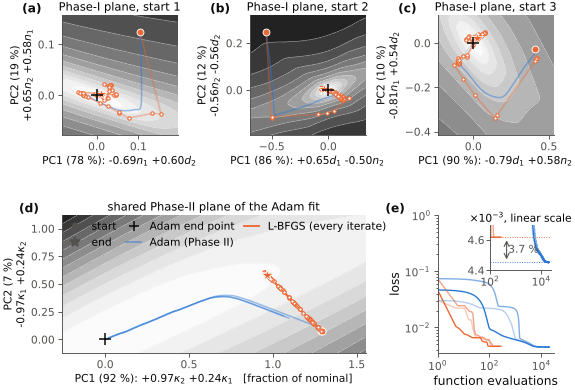

In [11]:
RES = 61
t0 = time.time()
grids1 = [lv.evaluate_plane(P.loss_np, pl, extent=extent_of(pl, [adam[k]['params'][:b + 1], runs[k]['params']]), res=RES, verbose=False)
          for k, pl in enumerate(planes1)]
ext2 = list(extent_of(plane2, [t['params'][b:] for t in adam] + [r['params'] for r in runs])); ext2[3] += 0.45 * (ext2[3] - ext2[2])   # headroom for the legend
grid2 = lv.evaluate_plane(P.loss_np, plane2, extent=tuple(ext2), res=RES, verbose=False)
print(f'planes evaluated on the extended windows in {time.time()-t0:.0f} s')
C_ADAM, C_LBFGS = ps.ROLE['adam'], ps.ROLE['lbfgs']
SHADE = [1.0, 0.6, 0.35]
fig = plt.figure(figsize=ps.figsize(1.0, height_cm=9.4))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.15], hspace=0.62, wspace=0.62, left=0.1, right=0.985, top=0.94, bottom=0.11)
vmin = min(g['Z'].min() for g in grids1); vmax = max(g['Z'].max() for g in grids1)
for k, g in enumerate(grids1):
    ax = fig.add_subplot(gs[0, k])
    lv._landscape(ax, g['a'], g['b'], g['Z'], cbar=False, vmin=vmin, vmax=vmax)
    a, bb, _ = lv.project(g['plane'], adam[k]['params'])
    ax.plot(a[:b + 1], bb[:b + 1], color=C_ADAM, lw=1.0, alpha=0.45, zorder=4)
    ax.plot(a[b:], bb[b:], color=C_ADAM, lw=0.6, alpha=0.2, zorder=4)
    a, bb, _ = lv.project(g['plane'], runs[k]['params'])
    draw_path(ax, a, bb, C_LBFGS, marker_every=True, milestones=[])
    ax.plot(0, 0, '+', color=ps.INK, ms=8, mew=1.0, zorder=20)
    ev = g['plane']['explained'] * 100
    ax.set_xlabel(f'PC1 ({ev[0]:.0f} %): {short_dir(g["plane"]["u"])}', fontsize=7)
    ax.set_ylabel(f'PC2 ({ev[1]:.0f} %)\n{short_dir(g["plane"]["v"])}', fontsize=7)
    ax.set_title(f'Phase-I plane, start {k+1}', fontsize=7.5)
    ax.set_xlim(g['a'][0], g['a'][-1]); ax.set_ylim(g['b'][0], g['b'][-1])
    ax.tick_params(labelsize=7); ax.locator_params(nbins=3)
    ps.panel_label(ax, 'abc'[k], x=-0.34, y=1.0)
ax = fig.add_subplot(gs[1, :2])
lv._landscape(ax, grid2['a'], grid2['b'], grid2['Z'], cbar=False)
for k in range(3):
    a, bb, _ = lv.project(plane2, adam[k]['params'])
    ax.plot(a[b:], bb[b:], color=C_ADAM, lw=1.0, alpha=0.45, zorder=4)
    a, bb, _ = lv.project(plane2, runs[k]['params'])
    draw_path(ax, a, bb, C_LBFGS, marker_every=True, milestones=[], annotate=False)
ax.plot(0, 0, '+', color=ps.INK, ms=8, mew=1.0, zorder=20)
ax.plot([], [], color=C_ADAM, lw=1.0, alpha=0.6, label='Adam (Phase II)')
ax.plot([], [], color=C_LBFGS, lw=1.2, label='L-BFGS (every iterate)')
ev = plane2['explained'] * 100
ax.set_xlabel(f'PC1 ({ev[0]:.0f} %): {short_dir(plane2["u"], 2)}   [fraction of nominal]', fontsize=7)
ax.set_ylabel(f'PC2 ({ev[1]:.0f} %)\n{short_dir(plane2["v"], 2)}', fontsize=7)
ax.set_title('shared Phase-II plane of the Adam fit', fontsize=7.5)
ax.set_xlim(grid2['a'][0], grid2['a'][-1]); ax.set_ylim(grid2['b'][0], grid2['b'][-1])
from matplotlib.lines import Line2D
h_ = [Line2D([], [], ls='', marker='o', color=ps.INK2, ms=4), Line2D([], [], ls='', marker='*', color=ps.INK2, ms=7), Line2D([], [], ls='', marker='+', color=ps.INK, ms=7, mew=1.0),
      Line2D([], [], color=C_ADAM, lw=1.0, alpha=0.6), Line2D([], [], color=C_LBFGS, lw=1.2)]
ax.legend(h_, ['start', 'end', 'Adam end point', 'Adam (Phase II)', 'L-BFGS (every iterate)'], loc='upper left', ncol=3, fontsize=7, columnspacing=0.9, handlelength=1.4, borderaxespad=0.2)
ax.tick_params(labelsize=7); ax.locator_params(nbins=5)
ps.panel_label(ax, 'd', x=-0.14, y=1.0)
ax = fig.add_subplot(gs[1, 2])
for k in range(3):
    ax.plot(np.arange(1, N_ADAM + 1), adam[k]['loss'], color=C_ADAM, lw=0.9, alpha=SHADE[k], label='Adam' if k == 0 else None)
    e = runs[k]['n_evals'].copy(); e[0] = 1
    ax.plot(e, runs[k]['loss'], color=C_LBFGS, lw=0.9, alpha=SHADE[k], label='L-BFGS' if k == 0 else None)
ax.set(xscale='log', yscale='log', xlabel='function evaluations', ylabel='loss'); ax.tick_params(labelsize=7)
ax.set_xlim(1, 3e4); ax.set_ylim(3.5e-3, 1); ps.despine(ax)          # colours as in (d)
ps.panel_label(ax, 'e', x=-0.45, y=1.0)
axin = ax.inset_axes([0.45, 0.6, 0.53, 0.33])
for k in range(3):
    axin.plot(np.arange(1, N_ADAM + 1), 1e3 * adam[k]['loss'], color=C_ADAM, lw=0.9, alpha=SHADE[k])
    e = runs[k]['n_evals'].copy(); e[0] = 1
    axin.plot(e, 1e3 * runs[k]['loss'], color=C_LBFGS, lw=0.9, alpha=SHADE[k])
l_st, l_ad = float(lbfgs_stall.mean()), float(adam_final.min())
axin.axhline(1e3 * l_st, color=C_LBFGS, lw=0.6, ls=':'); axin.axhline(1e3 * l_ad, color=C_ADAM, lw=0.6, ls=':')
axin.set_xscale('log'); axin.set_xlim(100, 2.5e4); axin.set_ylim(4.40, 4.70)
axin.annotate('', xy=(450, 1e3 * l_ad), xytext=(450, 1e3 * l_st), arrowprops=dict(arrowstyle='<->', color=ps.INK2, lw=0.7))
axin.text(520, 1e3 * 0.5 * (l_st + l_ad), f'{100*(l_st/l_ad-1):.1f} %', ha='left', va='center', fontsize=7, color=ps.INK2)
axin.set_yticks([4.4, 4.6]); axin.set_xticks([1e2, 1e4]); axin.tick_params(labelsize=7, pad=1)
axin.set_title(r'$\times10^{-3}$, linear scale', fontsize=7, pad=2)
ps.savefig(fig, '../figs/fig5_lbfgs_trajectory')
plt.show()
LOOP1['fig5_data'] = dict(lbfgs_stall_level_mean=l_st, adam_end_best=l_ad, gap_percent=100 * (l_st / l_ad - 1),
                          panels='(a)-(c) Phase-I planes of nb3 per start with every L-BFGS iterate; (d) shared Phase-II plane (restored, R30); (e) loss vs evaluations, inset linear y')

# Loop-2 check C17 — L-BFGS iterations to the end of Phase I
Phase I ends at the first iterate where the loss has fallen by 95 % of its total drop (start → end of the run), the criterion
used for Adam in Sec. 6.1.  Counted in L-BFGS iterations (accepted iterates) and in function evaluations.

In [12]:
def phase1_end(loss, frac=0.95):
    loss = np.asarray(loss); drop = loss[0] - loss[-1]
    return int(np.argmax(loss[0] - loss >= frac * drop))
c17 = []
for k in range(3):
    i = phase1_end(runs[k]['loss']); ia = phase1_end(adam[k]['loss'])
    c17.append(dict(start=k + 1, lbfgs_iterations=i, lbfgs_evaluations=int(runs[k]['n_evals'][i]), lbfgs_total_iterations=int(len(runs[k]['loss']) - 1),
                    adam_iterations_same_criterion=ia))
    print(f"start {k+1}: L-BFGS reaches 95 % of its loss drop at iteration {i} ({int(runs[k]['n_evals'][i])} evaluations; run length {len(runs[k]['loss'])-1} iterations); "
          f"Adam at iteration {ia}")
LOOP2 = dict(date='2026-11-24', source='reviews/loop2_domain.md',
             C17_lbfgs_phase1_iterations=dict(criterion='first iterate with loss(0) - loss(i) >= 0.95 (loss(0) - loss(end)); loss Eq. (4)', per_start=c17))
results['loop2_checks'] = LOOP2

start 1: L-BFGS reaches 95 % of its loss drop at iteration 8 (22 evaluations; run length 67 iterations); Adam at iteration 537
start 2: L-BFGS reaches 95 % of its loss drop at iteration 8 (28 evaluations; run length 74 iterations); Adam at iteration 1422
start 3: L-BFGS reaches 95 % of its loss drop at iteration 39 (96 evaluations; run length 80 iterations); Adam at iteration 1615


In [13]:
LOOP1['timings_s'] = T_LOOP1
LOOP1['figure_export'] = ps.FONT_LOG
results['loop1_checks'] = LOOP1
json.dump(ps.to_jsonable(results), open('../results/nb4.json', 'w'), indent=1)
print('wrote ../results/nb4.json with loop1_checks:', list(LOOP1))

wrote ../results/nb4.json with loop1_checks: ['date', 'source', 'C7_adam_learning_rate', 'C9_kink_probe', 'C10_out_of_plane', 'end_points_timing_invariants', 'fig5_data', 'timings_s', 'figure_export']
